# MM economics vs trading frequency (Binance–Hyperliquid toy)

How the five-term machine changes as you move from sub-second to multi-second to multi-minute holding times, and from fast to slow requoting.

**Everything here is synthetic.** The parameters are placeholders chosen to be plausible for a mid-cap coin at base-tier fees. The point is the *shape* of each curve, not the level. Replace them with numbers measured from your server data (see the last section).

Sections
1. The exit problem: why "spread captured" assumes you get out at fair, and the identity that fixes it
2. Analytic model: per-lot economics vs holding time, for three exit styles
3. Monte Carlo: a latency-aware Hyperliquid quoter hedging on Binance
4. Kearns (K − z²)/2: random walk vs mean-reverting series vs refresh interval
5. Interactive sliders (needs `ipywidgets`)
6. Your turn: what to replace with real data

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from dataclasses import dataclass, replace

plt.rcParams.update({
    "figure.figsize": (11, 4.8), "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
})
SEC_PER_YEAR = 365 * 24 * 3600

def vol_bp_per_sqrt_s(annual_vol):
    # annualised vol (0.80 = 80%) -> bp per sqrt(second)
    return annual_vol / np.sqrt(SEC_PER_YEAR) * 1e4

for v in (0.5, 0.8, 1.2):
    s = vol_bp_per_sqrt_s(v)
    print(f"{v:.0%} vol: {s:.2f} bp/sqrt(s) | 1 s {s:.1f} bp | 10 s {s*10**0.5:.1f} bp | 60 s {s*60**0.5:.1f} bp | 300 s {s*300**0.5:.1f} bp")

50% vol: 0.89 bp/sqrt(s) | 1 s 0.9 bp | 10 s 2.8 bp | 60 s 6.9 bp | 300 s 15.4 bp
80% vol: 1.42 bp/sqrt(s) | 1 s 1.4 bp | 10 s 4.5 bp | 60 s 11.0 bp | 300 s 24.7 bp
120% vol: 2.14 bp/sqrt(s) | 1 s 2.1 bp | 10 s 6.8 bp | 60 s 16.6 bp | 300 s 37.0 bp


## 1. The exit problem

"Spread captured" in the five-term breakdown is measured against **fair value at the moment of the fill**. It is only realised if you can close the position at fair, which you can't: closing is a second trade with its own cost. The honest per-lot identity (for a lot of side $d=+1$ long, $-1$ short; $F$ = true fair, the Binance mid) telescopes exactly:

$$
\text{P\&L}_{\text{lot}} = \underbrace{d\,(F^{q} - p_{\text{in}})}_{\text{quoted edge}}
+ \underbrace{d\,(F_{\text{fill}} - F^{q})}_{\text{staleness (adverse sel.)}}
+ \underbrace{d\,(F_{\text{exit}} - F_{\text{fill}})}_{\text{holding drift}}
+ \underbrace{d\,(p_{\text{out}} - F_{\text{exit}})}_{\text{exit vs fair}}
- \text{fees}
$$

where $F^{q}$ is the fair you used when you sent the quote. Every term changes with frequency:

| Term | Fast (hedge in ~1 s) | Slow (hold seconds–minutes) |
|---|---|---|
| Quoted edge | fixed by your half-spread | same, but inventory skew grows |
| Staleness | set by requote interval + ~750 ms latency | same per fill; you quote less often |
| Holding drift | ~0 mean, small variance | 0 mean on a random walk, **variance ∝ τ**; positive mean only if the thing you hold mean-reverts |
| Exit vs fair | pay Binance half-spread (taker) | can exit passively: earn a spread back, but passive exits are adversely selected too |
| Fees | HL maker + Binance taker (~6.5 bp) | HL maker ×2 if offset on HL (~3 bp) |

Three ways to "get out":
- **Taker hedge on Binance**: certain, fast, costs ~5 bp fee + half-spread.
- **Wait for an offsetting fill on Hyperliquid**: earns the spread again, but you wait (and carry price risk) and the offsetting fill can itself be informed.
- **Passive exit on Binance**: cheaper fee, but it fills when price moves *through* it, i.e. when you'd rather not have filled.

## 2. Analytic model: per-lot economics vs holding time τ

τ is the *maximum* holding time: you try your passive exit until τ, then hedge as taker. Simplifications (deliberate): holding time is exponential until the passive exit fills; adverse selection is split into an instant part (already in the price when you're filled) and a short post-fill drift; risk is diffusion only (no jumps); lots are independent. Throughput is capped by inventory via Little's law: open lots ≈ lot rate × mean holding time ≤ max inventory.

In [2]:
@dataclass
class Econ:
    annual_vol: float = 0.80
    half_spread: float = 6.0          # bp, your HL quote vs fair
    adverse_stale: float = 3.0        # bp, instant adverse selection per fill (already in price at fill)
    adverse_drift: float = 1.5        # bp, extra post-fill drift against you...
    adverse_tau: float = 2.0          # s, ...realised over this time scale
    fee_hl_maker: float = 1.5
    fee_bn_taker: float = 5.0
    fee_bn_maker: float = 2.0
    bn_half_spread: float = 0.5
    notify_latency: float = 0.3       # s, time until you learn of the HL fill
    fill_rate: float = 0.05           # HL fills per second you'd get with no inventory limit
    max_inventory: float = 5          # lots
    hl_offset_rate: float = 0.03      # /s, rate of an offsetting HL fill while you hold
    hl_offset_adverse: float = 2.0    # bp, adverse selection on that offsetting fill
    bn_passive_rate: float = 0.2      # /s, rate a passive Binance exit fills
    bn_passive_adverse: float = 1.0   # bp, adverse selection on a passive Binance exit

EXIT_MODES = ["taker hedge on Binance", "wait for HL offset", "passive exit on Binance"]

def per_lot(tau, p: Econ, mode):
    # Mean components (bp), std (bp), mean holding time (s) for one lot.
    tau = np.asarray(tau, float)
    s = vol_bp_per_sqrt_s(p.annual_vol)
    taker_exit = -p.bn_half_spread
    if mode == EXIT_MODES[0]:
        lam, passive_exit, passive_fee = 0.0, 0.0, 0.0
    elif mode == EXIT_MODES[1]:
        lam, passive_exit, passive_fee = p.hl_offset_rate, p.half_spread - p.hl_offset_adverse, p.fee_hl_maker
    else:
        lam, passive_exit, passive_fee = p.bn_passive_rate, p.bn_half_spread - p.bn_passive_adverse, p.fee_bn_maker
    p_pass = 1 - np.exp(-lam * tau) if lam > 0 else np.zeros_like(tau)
    hold = (p_pass / lam if lam > 0 else tau) + p.notify_latency      # E[min(T, tau)] + notify
    comp = {
        "quoted edge": np.full_like(tau, p.half_spread),
        "staleness": np.full_like(tau, -p.adverse_stale),
        "holding drift": -p.adverse_drift * (1 - np.exp(-hold / p.adverse_tau)),
        "exit vs fair": p_pass * passive_exit + (1 - p_pass) * taker_exit,
        "fees": -(p.fee_hl_maker + p_pass * passive_fee + (1 - p_pass) * p.fee_bn_taker),
    }
    mean = sum(comp.values())
    std = s * np.sqrt(hold)
    return comp, mean, std, hold, p_pass

def per_hour(tau, p: Econ, mode):
    comp, mean, std, hold, p_pass = per_lot(tau, p, mode)
    lots_hr = np.minimum(p.fill_rate, p.max_inventory / hold) * 3600     # Little's law cap
    pnl_hr = mean * lots_hr
    risk_hr = std * np.sqrt(lots_hr)
    return pnl_hr, risk_hr, lots_hr

P = Econ()
taus = np.logspace(-1, np.log10(900), 200)

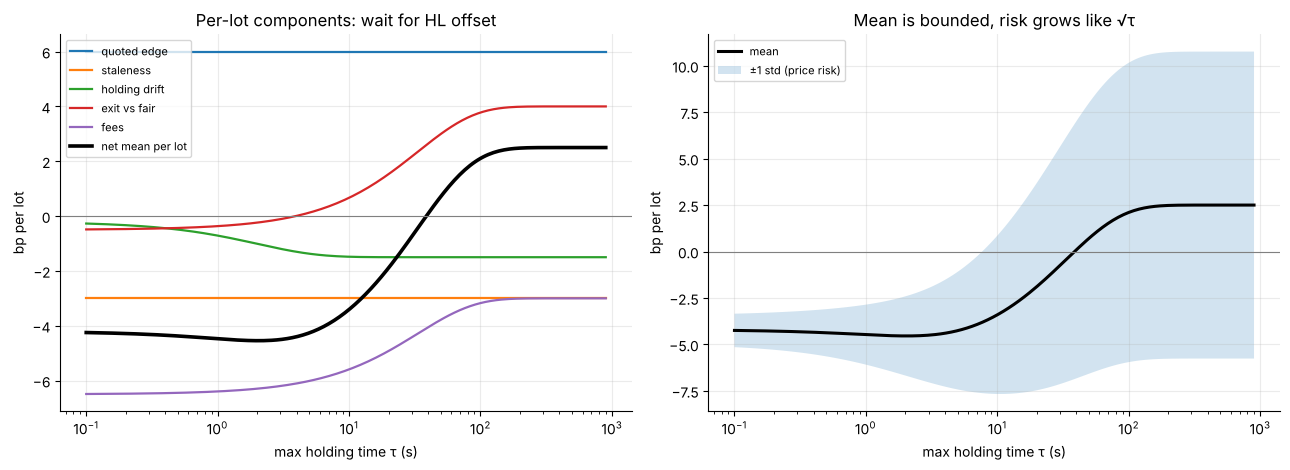

In [3]:
# Figure 1: where the money goes, per lot, for the "wait for HL offset" exit
mode = EXIT_MODES[1]
comp, mean, std, hold, p_pass = per_lot(taus, P, mode)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.8))
for k, v in comp.items():
    a1.plot(taus, v, label=k, lw=1.6)
a1.plot(taus, mean, "k", lw=2.6, label="net mean per lot")
a1.axhline(0, color="grey", lw=0.8)
a1.set_xscale("log"); a1.set_xlabel("max holding time τ (s)"); a1.set_ylabel("bp per lot")
a1.set_title(f"Per-lot components: {mode}"); a1.legend(fontsize=8)

a2.plot(taus, mean, "k", lw=2.2, label="mean")
a2.fill_between(taus, mean - std, mean + std, alpha=0.2, label="±1 std (price risk)")
a2.axhline(0, color="grey", lw=0.8)
a2.set_xscale("log"); a2.set_xlabel("max holding time τ (s)"); a2.set_ylabel("bp per lot")
a2.set_title("Mean is bounded, risk grows like √τ"); a2.legend(fontsize=8)
plt.tight_layout(); plt.show()

Read it like this: holding longer buys you a cheaper exit (more lots close on Hyperliquid at a spread instead of paying the Binance taker fee), so the **mean** per lot rises and then saturates. The **risk** per lot keeps growing like √τ. Past a point you're paying a lot of variance for nothing.

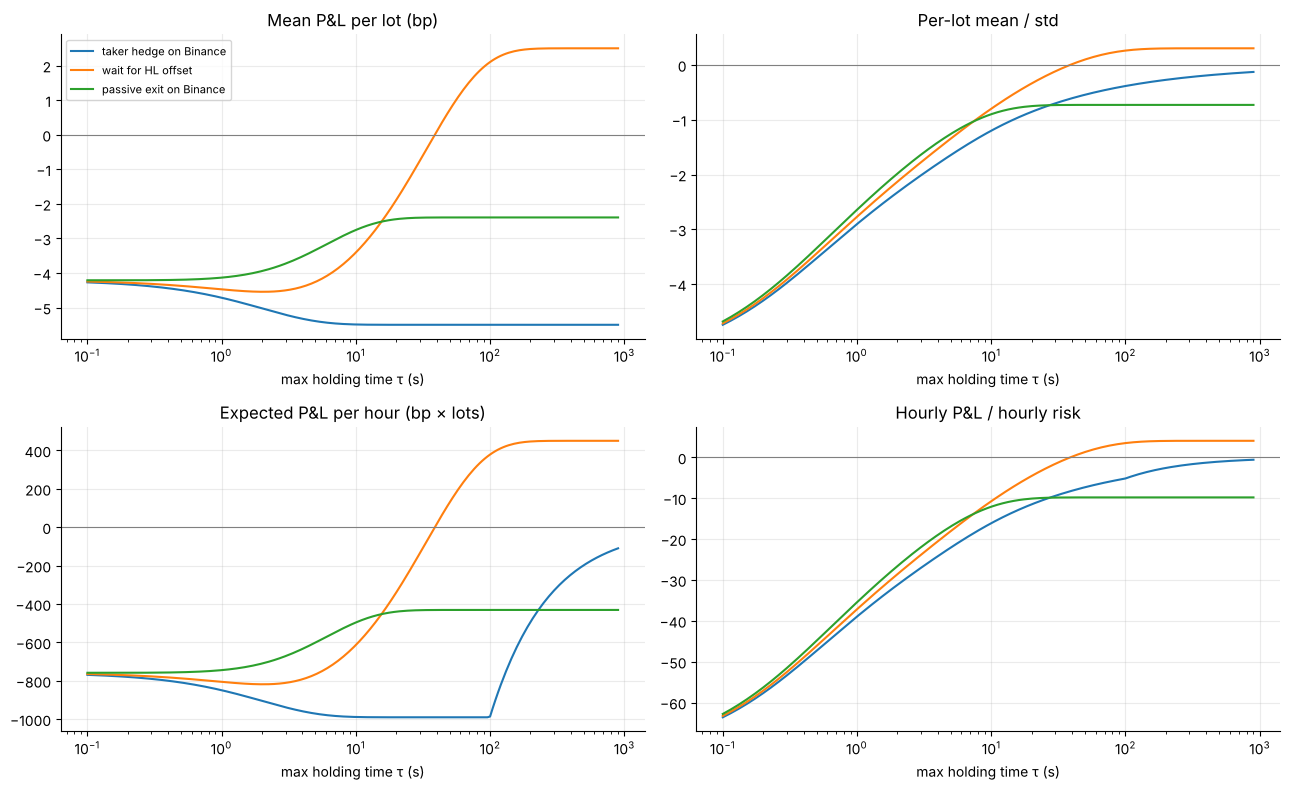

mean holding (s) at τ = 1, 10, 60, 300 s (HL offset mode): [ 1.3  8.9 28.1 33.6]
Throughput cap: max_inventory / mean holding -> lots per hour fall once holding binds


In [4]:
# Figure 2: the three exit styles, per lot and per hour
fig, axs = plt.subplots(2, 2, figsize=(13, 8))
for m in EXIT_MODES:
    _, mean, std, hold, p_pass = per_lot(taus, P, m)
    pnl_hr, risk_hr, lots_hr = per_hour(taus, P, m)
    axs[0, 0].plot(taus, mean, label=m)
    axs[0, 1].plot(taus, mean / std, label=m)
    axs[1, 0].plot(taus, pnl_hr, label=m)
    axs[1, 1].plot(taus, pnl_hr / risk_hr, label=m)
titles = ["Mean P&L per lot (bp)", "Per-lot mean / std", "Expected P&L per hour (bp × lots)", "Hourly P&L / hourly risk"]
for ax, t in zip(axs.flat, titles):
    ax.set_xscale("log"); ax.axhline(0, color="grey", lw=0.8); ax.set_title(t); ax.set_xlabel("max holding time τ (s)")
axs[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.show()

_, _, _, hold, _ = per_lot(np.array([1.0, 10, 60, 300]), P, EXIT_MODES[1])
print("mean holding (s) at τ = 1, 10, 60, 300 s (HL offset mode):", np.round(hold, 1))
print("Throughput cap: max_inventory / mean holding -> lots per hour fall once holding binds")

## 3. Monte Carlo: the machine with latency

A minimal event simulation at 100 ms steps:
- **Binance mid** $B_t$: random walk plus occasional jumps. This is the true fair.
- **Hyperliquid mid** $H_t$: Binance lagged by `hl_lag` plus a mean-reverting (OU) basis.
- **You** see Binance with `feed_latency`, quote on HL at fair ± half-spread (skewed by inventory), re-centre every `requote_every` seconds or when fair moves more than `requote_thresh`. Every quote change goes live after **750 ± 100 ms**.
- **Takers**: uninformed arrivals hit you with an intensity that decays with distance from the HL mid; **informed arbs** hit any quote that Binance has moved through by more than `arb_threshold`.
- **Exit**: an opposite HL fill closes your oldest open lot (HL offset); otherwise each lot is hedged as taker on Binance after `hold_max` (never before you'd know about it: `notify_latency`).

Every closed lot is decomposed with the identity from section 1, so the components add up exactly.

In [5]:
@dataclass
class SimCfg:
    hours: float = 2.0
    dt: float = 0.1
    annual_vol: float = 0.80
    jump_rate: float = 1 / 120        # Binance jumps per second
    jump_bp: float = 6.0              # jump size std (bp)
    hl_lag: float = 0.3               # s, HL mid follows Binance with this lag
    basis_std: float = 1.0            # bp, stationary std of HL-Binance basis noise
    basis_half_life: float = 5.0      # s
    half_spread: float = 6.0          # bp
    requote_every: float = 1.0        # s
    requote_thresh: float = 2.0       # bp
    hl_latency: float = 0.75          # s
    hl_latency_jitter: float = 0.10   # s (uniform ±)
    feed_latency: float = 0.05        # s
    notify_latency: float = 0.3       # s
    hold_max: float = 5.0             # s, then taker hedge on Binance
    max_inventory: int = 5
    skew_bp_per_unit: float = 1.0
    uninformed_rate: float = 0.03     # /s per side when quoting at the HL mid
    uninformed_k: float = 0.25        # intensity decay per bp from HL mid
    arb_threshold: float = 3.0        # bp
    fee_hl_maker: float = 1.5
    fee_bn_taker: float = 5.0
    bn_half_spread: float = 0.5

COMPONENTS = ["quoted edge", "staleness", "holding drift", "exit vs fair", "fees"]

def simulate(c: SimCfg, seed=0, record=False):
    rng = np.random.default_rng(seed)
    n = int(c.hours * 3600 / c.dt)
    sig = vol_bp_per_sqrt_s(c.annual_vol) * np.sqrt(c.dt)
    jumps = (rng.random(n) < c.jump_rate * c.dt) * rng.normal(0, c.jump_bp, n)
    B = np.cumsum(rng.normal(0, sig, n) + jumps)
    phi = np.exp(-np.log(2) * c.dt / c.basis_half_life)
    eps = rng.normal(0, c.basis_std * np.sqrt(1 - phi**2), n)
    basis = np.empty(n); basis[0] = 0.0
    for t in range(1, n):
        basis[t] = phi * basis[t - 1] + eps[t]
    lag = int(round(c.hl_lag / c.dt))
    H = np.concatenate([np.full(lag, B[0]), B[:n - lag]]) + basis
    feed = int(round(c.feed_latency / c.dt))
    notify = max(1, int(round(c.notify_latency / c.dt)))
    hold = max(notify, int(round(c.hold_max / c.dt)))
    requote = max(1, int(round(c.requote_every / c.dt)))
    u_bid, u_ask = rng.random(n), rng.random(n)

    pending = []                      # (activate_step, send_step, bid, ask, quote_fair)
    bid = ask = np.nan; q_fair = B[0]; applied_send = -1
    last_sent, last_fair, force_at = -10**9, None, -1
    lots = []                         # open lots: [d, entry_px, entry_step, quote_fair, informed, due]
    closed = []                       # rows: d, in_px, in_step, q_fair, informed, out_px, out_step, exit_type
    rec_bid = np.full(n, np.nan) if record else None
    rec_ask = np.full(n, np.nan) if record else None
    fills = []                        # (step, d, px, informed)

    def inventory():
        return sum(l[0] for l in lots)

    def on_fill(t, d, px, informed):
        fills.append((t, d, px, informed))
        for i, l in enumerate(lots):                    # offset oldest opposite lot on HL
            if l[0] == -d:
                lots.pop(i)
                closed.append((l[0], l[1], l[2], l[3], l[4], px, t, "HL offset"))
                return
        lots.append([d, px, t, q_fair, informed, t + hold])

    for t in range(n):
        if pending:                                     # activate quote updates that have landed
            ready = [p for p in pending if p[0] <= t and p[1] > applied_send]
            if ready:                                   # newest decision wins; a late-arriving older one is ignored
                _, applied_send, bid, ask, q_fair = max(ready, key=lambda p: p[1])
            pending = [p for p in pending if p[0] > t and p[1] > applied_send]
        # informed arbs: Binance already through your stale quote
        if ask == ask and B[t] - ask > c.arb_threshold:
            on_fill(t, -1, ask, True); ask = np.nan; force_at = t + notify
        if bid == bid and bid - B[t] > c.arb_threshold:
            on_fill(t, +1, bid, True); bid = np.nan; force_at = t + notify
        # uninformed takers
        if ask == ask and u_ask[t] < c.uninformed_rate * c.dt * np.exp(-c.uninformed_k * max(0.0, ask - H[t])):
            on_fill(t, -1, ask, False); ask = np.nan; force_at = t + notify
        if bid == bid and u_bid[t] < c.uninformed_rate * c.dt * np.exp(-c.uninformed_k * max(0.0, H[t] - bid)):
            on_fill(t, +1, bid, False); bid = np.nan; force_at = t + notify
        # taker hedge on Binance for lots past their holding limit
        if lots and lots[0][5] <= t:
            keep = []
            for l in lots:
                if l[5] <= t:
                    closed.append((l[0], l[1], l[2], l[3], l[4], B[t] - l[0] * c.bn_half_spread, t, "Binance taker"))
                else:
                    keep.append(l)
            lots = keep
        # requote decision on (slightly stale) Binance fair
        fair = B[max(0, t - feed)]
        if t - last_sent >= requote or t == force_at or last_fair is None or abs(fair - last_fair) > c.requote_thresh:
            inv = inventory()
            nb = fair - c.half_spread - c.skew_bp_per_unit * inv
            na = fair + c.half_spread - c.skew_bp_per_unit * inv
            if inv >= c.max_inventory: nb = np.nan
            if inv <= -c.max_inventory: na = np.nan
            lat = c.hl_latency + rng.uniform(-c.hl_latency_jitter, c.hl_latency_jitter)
            pending.append((t + max(1, int(round(lat / c.dt))), t, nb, na, fair))
            last_sent, last_fair = t, fair
        if record:
            rec_bid[t], rec_ask[t] = bid, ask
    for l in lots:                                      # flatten at the end
        closed.append((l[0], l[1], l[2], l[3], l[4], B[-1] - l[0] * c.bn_half_spread, n - 1, "Binance taker"))

    d = np.array([r[0] for r in closed], float)
    p_in = np.array([r[1] for r in closed]); s_in = np.array([r[2] for r in closed])
    qf = np.array([r[3] for r in closed]); inf = np.array([r[4] for r in closed])
    p_out = np.array([r[5] for r in closed]); s_out = np.array([r[6] for r in closed])
    offset = np.array([r[7] == "HL offset" for r in closed])
    comp = {
        "quoted edge": d * (qf - p_in),
        "staleness": d * (B[s_in] - qf),
        "holding drift": d * (B[s_out] - B[s_in]),
        "exit vs fair": d * (p_out - B[s_out]),
        "fees": -(c.fee_hl_maker + np.where(offset, c.fee_hl_maker, c.fee_bn_taker)),
    }
    pnl = sum(comp.values())
    assert np.allclose(pnl, d * (p_out - p_in) + comp["fees"])
    out = dict(B=B, H=H, comp=comp, pnl=pnl, informed=inf, offset=offset,
               hold_s=(s_out - s_in) * c.dt, s_out=s_out, fills=fills, cfg=c, n=n)
    if record:
        out.update(bid=rec_bid, ask=rec_ask)
    return out

def summarise(res):
    c, pnl = res["cfg"], res["pnl"]
    hours = c.hours
    buckets = np.bincount((res["s_out"] * c.dt // 300).astype(int), weights=pnl, minlength=int(hours * 12))
    return dict(lots_hr=len(pnl) / hours, mean=pnl.mean(), std=pnl.std(), pnl_hr=pnl.sum() / hours,
                sharpe_hr=buckets.mean() / (buckets.std() + 1e-9) * np.sqrt(12),
                informed=res["informed"].mean(), offset=res["offset"].mean(),
                comp={k: v.mean() for k, v in res["comp"].items()})

base = SimCfg()
res = simulate(base, seed=1, record=True)
s = summarise(res)
print(f"lots/hr {s['lots_hr']:.0f} | mean {s['mean']:.2f} bp | std {s['std']:.2f} bp | "
      f"informed share {s['informed']:.0%} | HL-offset share {s['offset']:.0%} | P&L/hr {s['pnl_hr']:.0f} bp")
print({k: round(v, 2) for k, v in s['comp'].items()})

lots/hr 54 | mean -2.58 bp | std 5.39 bp | informed share 13% | HL-offset share 4% | P&L/hr -138 bp
{'quoted edge': np.float64(6.02), 'staleness': np.float64(-1.81), 'holding drift': np.float64(0.04), 'exit vs fair': np.float64(-0.46), 'fees': np.float64(-6.37)}


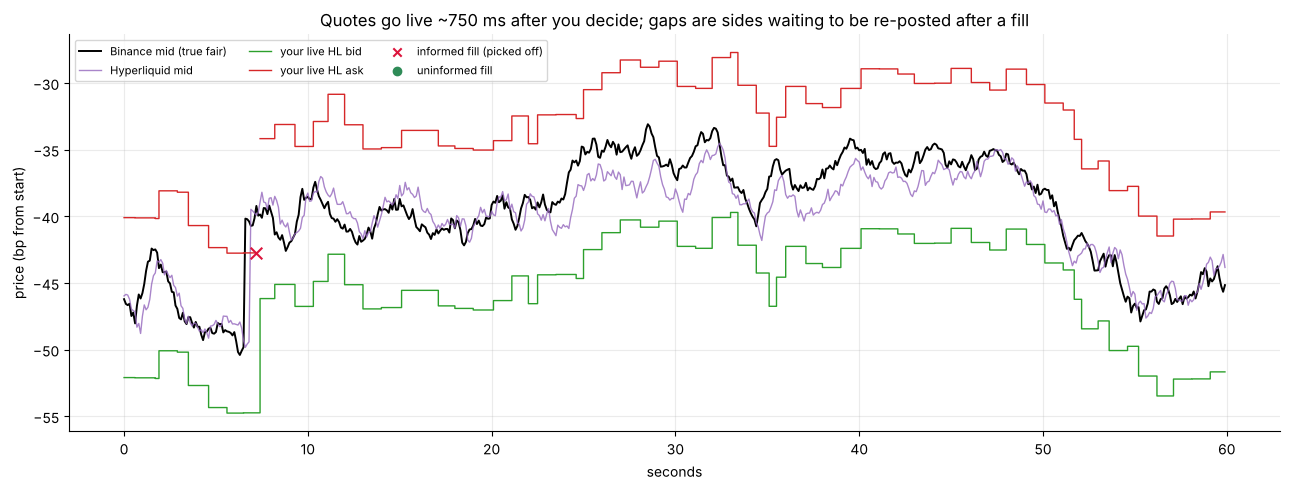

In [6]:
# Figure 3: one minute of the machine. Watch quotes lag Binance and arbs pick them off.
c = res["cfg"]; t0 = int(1800 / c.dt); w = int(60 / c.dt)
tt = np.arange(t0, t0 + w) * c.dt - t0 * c.dt
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(tt, res["B"][t0:t0 + w], color="k", lw=1.4, label="Binance mid (true fair)")
ax.plot(tt, res["H"][t0:t0 + w], color="tab:purple", lw=1, alpha=0.8, label="Hyperliquid mid")
ax.step(tt, res["bid"][t0:t0 + w], where="post", color="tab:green", lw=1, label="your live HL bid")
ax.step(tt, res["ask"][t0:t0 + w], where="post", color="tab:red", lw=1, label="your live HL ask")
for (st, d, px, inf) in res["fills"]:
    if t0 <= st < t0 + w:
        ax.scatter((st - t0) * c.dt, px, marker="x" if inf else "o", s=70 if inf else 35,
                   color="crimson" if inf else "seagreen", zorder=5)
ax.scatter([], [], marker="x", color="crimson", label="informed fill (picked off)")
ax.scatter([], [], marker="o", color="seagreen", label="uninformed fill")
ax.set_xlabel("seconds"); ax.set_ylabel("price (bp from start)"); ax.legend(fontsize=8, ncol=3)
ax.set_title("Quotes go live ~750 ms after you decide; gaps are sides waiting to be re-posted after a fill")
plt.tight_layout(); plt.show()

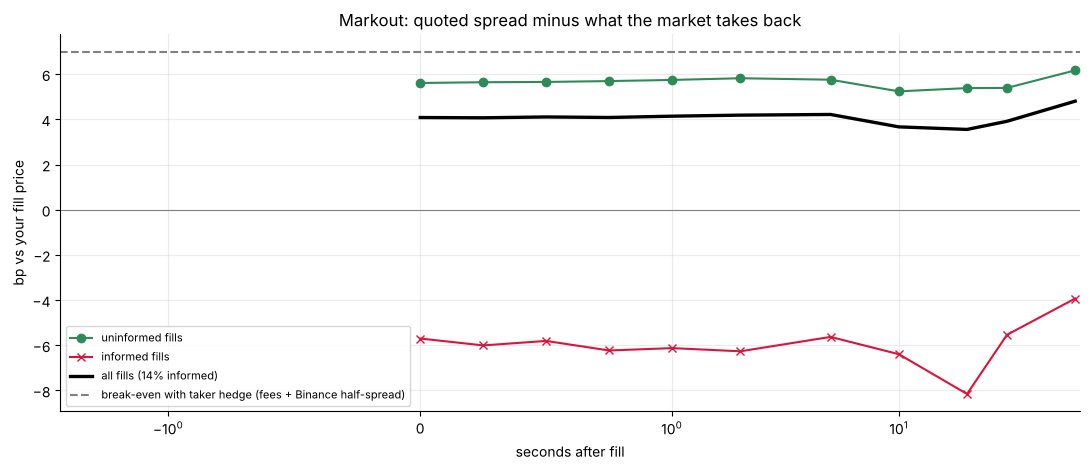

In [7]:
# Figure 4: markout curves. This is "spread captured" realised over time, against the true fair.
def markouts(res, horizons_s):
    c, B = res["cfg"], res["B"]
    out = {True: [], False: []}
    f = np.array([(st, d, px, inf) for st, d, px, inf in res["fills"]], float)
    for h in horizons_s:
        k = int(round(h / c.dt))
        ok = f[:, 0] + k < len(B)
        st = f[ok, 0].astype(int); d = f[ok, 1]; px = f[ok, 2]; inf = f[ok, 3].astype(bool)
        m = d * (B[st + k] - px)
        out[True].append(m[inf].mean()); out[False].append(m[~inf].mean())
    return out

hs = np.array([0, 0.25, 0.5, 0.75, 1, 2, 5, 10, 20, 30, 60])
mk = markouts(res, hs)
allf = np.array([f[3] for f in res["fills"]], bool)
blend = np.array(mk[True]) * allf.mean() + np.array(mk[False]) * (1 - allf.mean())
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.plot(hs, mk[False], "o-", color="seagreen", label="uninformed fills")
ax.plot(hs, mk[True], "x-", color="crimson", label="informed fills")
ax.plot(hs, blend, "k-", lw=2.4, label=f"all fills ({allf.mean():.0%} informed)")
ax.axhline(base.fee_hl_maker + base.fee_bn_taker + base.bn_half_spread, ls="--", color="grey",
           label="break-even with taker hedge (fees + Binance half-spread)")
ax.axhline(0, color="grey", lw=0.8)
ax.set_xscale("symlog", linthresh=1); ax.set_xlabel("seconds after fill"); ax.set_ylabel("bp vs your fill price")
ax.set_title("Markout: quoted spread minus what the market takes back"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

The black curve at 0 s is roughly "spread captured vs fair". Its level at your exit time is what you actually keep before fees. If it sits below the dashed line at every horizon, no holding-time choice saves you; only a wider spread, fewer informed fills, or cheaper exits do.

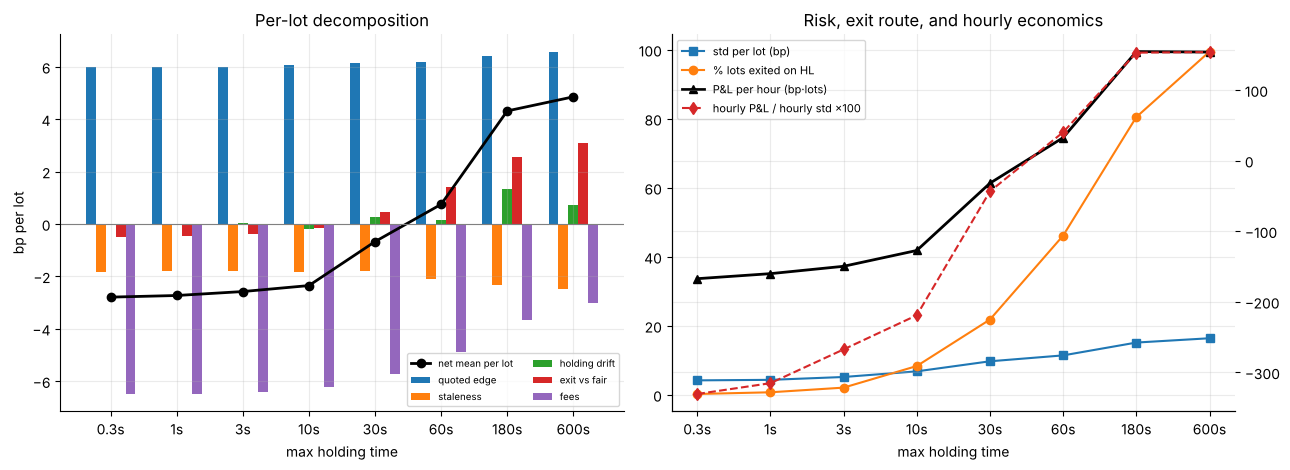

hold   0.3s | lots/hr     59 | mean  -2.79 | std   4.19 | HL exit   0% | P&L/hr    -167 | P&L/std per hr -3.31
hold     1s | lots/hr     58 | mean  -2.73 | std   4.34 | HL exit   1% | P&L/hr    -160 | P&L/std per hr -3.15
hold     3s | lots/hr     57 | mean  -2.58 | std   5.17 | HL exit   2% | P&L/hr    -150 | P&L/std per hr -2.68
hold    10s | lots/hr     54 | mean  -2.35 | std   6.80 | HL exit   8% | P&L/hr    -127 | P&L/std per hr -2.19
hold    30s | lots/hr     48 | mean  -0.67 | std   9.72 | HL exit  22% | P&L/hr     -32 | P&L/std per hr -0.44
hold    60s | lots/hr     41 | mean   0.75 | std  11.43 | HL exit  46% | P&L/hr      33 | P&L/std per hr 0.40
hold   180s | lots/hr     34 | mean   4.31 | std  15.15 | HL exit  80% | P&L/hr     154 | P&L/std per hr 1.53
hold   600s | lots/hr     31 | mean   4.85 | std  16.39 | HL exit  99% | P&L/hr     154 | P&L/std per hr 1.54


In [8]:
# Figure 5-6: sweep the maximum holding time
holds = [0.3, 1, 3, 10, 30, 60, 180, 600]
seeds = [1, 2, 3]
rows = []
for hm in holds:
    ss = [summarise(simulate(replace(base, hold_max=hm), seed=sd)) for sd in seeds]
    rows.append({k: np.mean([x[k] for x in ss]) for k in ["lots_hr", "mean", "std", "pnl_hr", "sharpe_hr", "offset", "informed"]}
                | {"comp": {k: np.mean([x["comp"][k] for x in ss]) for k in COMPONENTS}})

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.8))
x = np.arange(len(holds)); w = 0.15
for i, k in enumerate(COMPONENTS):
    a1.bar(x + (i - 2) * w, [r["comp"][k] for r in rows], w, label=k)
a1.plot(x, [r["mean"] for r in rows], "ko-", lw=2, label="net mean per lot")
a1.axhline(0, color="grey", lw=0.8); a1.set_xticks(x, [f"{h:g}s" for h in holds])
a1.set_xlabel("max holding time"); a1.set_ylabel("bp per lot"); a1.set_title("Per-lot decomposition"); a1.legend(fontsize=7, ncol=2)

a2.plot(x, [r["std"] for r in rows], "s-", label="std per lot (bp)")
a2.plot(x, [100 * r["offset"] for r in rows], "o-", label="% lots exited on HL")
a2b = a2.twinx()
a2b.plot(x, [r["pnl_hr"] for r in rows], "k^-", lw=2, label="P&L per hour (bp·lots)")
a2b.plot(x, [r["sharpe_hr"] * 100 for r in rows], "d--", color="tab:red", label="hourly P&L / hourly std ×100")
a2.set_xticks(x, [f"{h:g}s" for h in holds]); a2.set_xlabel("max holding time")
a2.set_title("Risk, exit route, and hourly economics")
h1, l1 = a2.get_legend_handles_labels(); h2, l2 = a2b.get_legend_handles_labels()
a2.legend(h1 + h2, l1 + l2, fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

for h, r in zip(holds, rows):
    print(f"hold {h:>5g}s | lots/hr {r['lots_hr']:6.0f} | mean {r['mean']:6.2f} | std {r['std']:6.2f} | "
          f"HL exit {r['offset']:4.0%} | P&L/hr {r['pnl_hr']:7.0f} | P&L/std per hr {r['sharpe_hr']:.2f}")

**Don't over-read the holding sweep.** In this toy, uninformed takers arrive symmetrically whatever the price is doing, so an offsetting Hyperliquid fill always turns up eventually and holding longer mostly buys you a cheaper exit. Real flow trends: in a move you accumulate inventory on the wrong side and the offsetting side dries up exactly when you need it. The result above is only as good as `uninformed_rate` being independent of direction. The number to measure is the offset rate *conditional on* the recent Binance move.

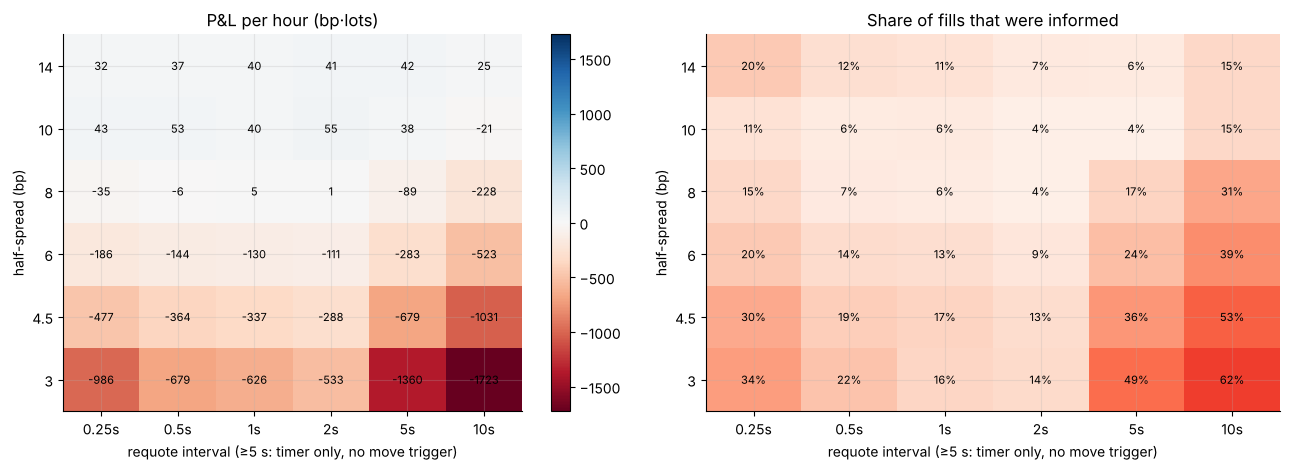

In [9]:
# Figure 7: quoting frequency vs width. How often you re-centre and how wide you quote, with your latency fixed.
req = [0.25, 0.5, 1, 2, 5, 10]
widths = [3, 4.5, 6, 8, 10, 14]
grid = np.zeros((len(widths), len(req))); inf_grid = np.zeros_like(grid)
for i, hs_ in enumerate(widths):
    for j, rq in enumerate(req):
        ss = [summarise(simulate(replace(base, half_spread=hs_, requote_every=rq, requote_thresh=1e9 if rq >= 5 else base.requote_thresh, hours=1.0), seed=sd)) for sd in (1, 2)]
        grid[i, j] = np.mean([x["pnl_hr"] for x in ss]); inf_grid[i, j] = np.mean([x["informed"] for x in ss])

fig, axs = plt.subplots(1, 2, figsize=(13, 4.8))
lim = np.abs(grid).max()
im = axs[0].imshow(grid, cmap="RdBu", vmin=-lim, vmax=lim, aspect="auto", origin="lower")
axs[1].imshow(inf_grid, cmap="Reds", vmin=0, vmax=1, aspect="auto", origin="lower")
for ax, g, fmt, t in [(axs[0], grid, "{:.0f}", "P&L per hour (bp·lots)"), (axs[1], inf_grid, "{:.0%}", "Share of fills that were informed")]:
    ax.set_xticks(range(len(req)), [f"{r:g}s" for r in req]); ax.set_yticks(range(len(widths)), [f"{w:g}" for w in widths])
    ax.set_xlabel("requote interval (≥5 s: timer only, no move trigger)"); ax.set_ylabel("half-spread (bp)"); ax.set_title(t)
    for i in range(g.shape[0]):
        for j in range(g.shape[1]):
            ax.text(j, i, fmt.format(g[i, j]), ha="center", va="center", fontsize=8)
plt.colorbar(im, ax=axs[0]); plt.tight_layout(); plt.show()

Two things to notice. Width does most of the work: below roughly the fee-plus-staleness level, nothing else rescues the book. And requoting faster than your latency does not make quotes fresher: every update still lands ~750 ms late, so very fast requoting mostly re-posts stale quotes into a market that is still moving, and the informed share rises again on the left. Somewhere between "once per latency" and "a few seconds" is the toy's sweet spot; where it is for you depends on how much of each move Binance has finished by the time your quote lands.

## 4. Kearns: (K − z²)/2 on a random walk vs a mean-reverting series

Chakraborty & Kearns (2011) ladder: buy orders at every tick below the last price and sell orders at every tick above it, refreshed every L steps, inventory liquidated at the end. With refresh every step, profit is exactly (K − z²)/2: zero in expectation on a unit-step random walk, positive and growing with time on an Ornstein–Uhlenbeck series. In your book the OU-like series is the **Hyperliquid–Binance basis**, not the price.

Left: their refresh-interval experiment (unit-ish steps), plus a per-fill fee that their model leaves out. Right: what happens when the price moves several ticks between refreshes, which is what a ~750 ms stale window does on a fine-tick book. Levels the price jumps straight through fill at stale prices; that is adverse selection appearing inside their own formula.

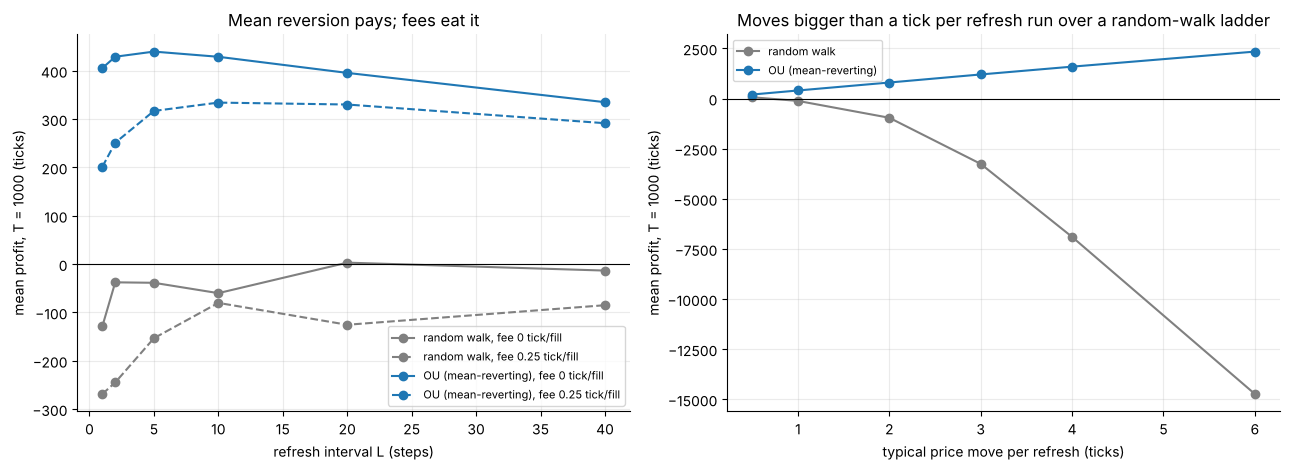

In [10]:
def kearns_ladder(P, L, fee=0.0):
    # P: integer price path. Buys at p0-1, p0-2, ... and sells at p0+1, ... ; each level fills once per refresh window.
    cash, inv, fills = 0.0, 0, 0
    for i in range(0, len(P) - 1, L):
        p0 = P[i]; seg = P[i + 1:i + L + 1]
        nb = max(0, p0 - seg.min()); ns = max(0, seg.max() - p0)
        cash += -(nb * p0 - nb * (nb + 1) / 2) + (ns * p0 + ns * (ns + 1) / 2)
        inv += nb - ns; fills += nb + ns
    return cash + inv * P[-1] - fee * fills

def paths(kind, T, rng, gamma=0.1, sigma=1.0, scale=1.0):
    e = rng.normal(0, sigma, T)
    if kind == "random walk":
        q = np.cumsum(e)
    else:
        q = np.zeros(T)
        for t in range(1, T):
            q[t] = (1 - gamma) * q[t - 1] + e[t]
    return np.rint(q * scale).astype(int) + 10_000

rng = np.random.default_rng(7)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.8))
Ls = [1, 2, 5, 10, 20, 40]
for kind, col in [("random walk", "grey"), ("OU (mean-reverting)", "tab:blue")]:
    for fee, ls in [(0.0, "-"), (0.25, "--")]:
        prof = [np.mean([kearns_ladder(paths(kind, 1000, rng), L, fee) for _ in range(300)]) for L in Ls]
        a1.plot(Ls, prof, ls, marker="o", color=col, label=f"{kind}, fee {fee:g} tick/fill")
a1.axhline(0, color="k", lw=0.8); a1.set_xlabel("refresh interval L (steps)"); a1.set_ylabel("mean profit, T = 1000 (ticks)")
a1.set_title("Mean reversion pays; fees eat it"); a1.legend(fontsize=8)

scales = [0.5, 1, 2, 3, 4, 6]
for kind, col in [("random walk", "grey"), ("OU (mean-reverting)", "tab:blue")]:
    prof = [np.mean([kearns_ladder(paths(kind, 1000, rng, scale=sc), 1) for _ in range(300)]) for sc in scales]
    a2.plot(scales, prof, marker="o", color=col, label=kind)
a2.axhline(0, color="k", lw=0.8); a2.set_xlabel("typical price move per refresh (ticks)"); a2.set_ylabel("mean profit, T = 1000 (ticks)")
a2.set_title("Moves bigger than a tick per refresh run over a random-walk ladder"); a2.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 5. Interactive: drag the analytic model

In [11]:
try:
    import ipywidgets as W
    def _plot(annual_vol, half_spread, adverse_stale, fee_bn_taker, hl_offset_rate, max_inventory):
        p = replace(P, annual_vol=annual_vol, half_spread=half_spread, adverse_stale=adverse_stale,
                    fee_bn_taker=fee_bn_taker, hl_offset_rate=hl_offset_rate, max_inventory=max_inventory)
        fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.2))
        for m in EXIT_MODES:
            _, mean, std, _, _ = per_lot(taus, p, m)
            pnl_hr, risk_hr, _ = per_hour(taus, p, m)
            a1.plot(taus, mean, label=m); a2.plot(taus, pnl_hr / risk_hr, label=m)
        for a, t in [(a1, "Mean P&L per lot (bp)"), (a2, "Hourly P&L / hourly risk")]:
            a.set_xscale("log"); a.axhline(0, color="grey", lw=0.8); a.set_title(t); a.set_xlabel("max holding τ (s)")
        a1.legend(fontsize=8); plt.tight_layout(); plt.show()
    W.interact(_plot,
               annual_vol=W.FloatSlider(value=0.8, min=0.2, max=2.0, step=0.05),
               half_spread=W.FloatSlider(value=6, min=1, max=20, step=0.5),
               adverse_stale=W.FloatSlider(value=3, min=0, max=10, step=0.25),
               fee_bn_taker=W.FloatSlider(value=5, min=1, max=6, step=0.25),
               hl_offset_rate=W.FloatLogSlider(value=0.03, base=10, min=-3, max=0),
               max_inventory=W.IntSlider(value=5, min=1, max=30))
except ImportError:
    print("pip install ipywidgets for the sliders")

pip install ipywidgets for the sliders


## 6. Your turn: replace the toy numbers

Each placeholder maps to something you can measure from your server data. Before you run anything, write down what you expect each to be:

- [ ] `adverse_stale`, `adverse_drift`, `adverse_tau`: from the markout curve of real Hyperliquid fills against the Binance mid. What does the curve look like between 0 and 2 s?
- [ ] `hl_offset_rate` and `hl_offset_adverse`: how often an opposite fill arrives while you hold, and how good it is.
- [ ] `basis_std`, `basis_half_life`: fit an OU to the HL–Binance mid difference. Is the half-life shorter or longer than your 750 ms?
- [ ] `uninformed_rate`, `uninformed_k`, `arb_threshold`: the hardest to identify. What would you need to observe to separate informed from uninformed fills?
- [ ] Your firm's real fee tier on both venues.

Then: at what holding time does the hourly risk-adjusted curve peak for your numbers, and which single parameter moves that peak the most?


## 7. Holding time: the same five-term machine, with different weights

This section keeps the original economics but reorganises them into the five practical levers:

$$
\text{Economic value}
=
\text{spread capture}
+
\text{adverse selection}
+
\text{fees/rebates}
+
\text{hedge cost}
+
\text{inventory cost}.
$$

The last four terms are usually negative, so equivalently:

$$
\text{Economic value}
\approx
\text{spread capture}
-
\text{adverse selection}
-
\text{fees}
-
\text{hedge cost}
-
\text{inventory risk cost}.
$$

This is a **re-labelling of the existing notebook**, not a new model:

- `quoted edge` becomes **spread capture**;
- `staleness` and short post-fill drift become **adverse selection**;
- `fees` remain **fees/rebates**;
- the taker component of `exit vs fair` becomes **hedge cost**;
- `holding drift` is the realised inventory P&L.

One subtle point matters: if fair value is a martingale, inventory price movement has **zero expected P&L**. Holding longer increases its variance, not automatically its negative mean. Therefore the analytic five-lever chart treats inventory cost as a **risk / certainty-equivalent penalty**, while the simulated equity paths show actual random mark-to-market inventory P&L.

The baseline here uses approximately **750 ms Hyperliquid quote latency** and **10 ms Binance hedge execution latency**. We then vary how long we are willing to carry the position before forcing the Binance hedge.


In [ ]:

from pathlib import Path
import sys

# Keep mm_holding_time_model.py beside this notebook.
sys.path.insert(0, str(Path.cwd()))

import mm_holding_time_model as mm

P_HOLD = mm.HoldingTimeParams(
    hl_quote_latency_s=0.75,
    bn_hedge_latency_s=0.01,
)

HOLDS = [0.75, 1, 2, 5, 10, 30, 60, 120]

sweep = mm.holding_sweep(HOLDS, P_HOLD)

mm.lever_table(HOLDS, P_HOLD)



### What should change as holding time rises?

The **entry spread** and the initial stale-fill problem are mostly determined at the time of the first fill, so extending the holding horizon does not make them disappear.

What changes materially is the **exit route**. With more time, there is a greater chance that an offsetting passive Hyperliquid fill arrives before the forced Binance hedge. That can improve economics because you avoid Binance taker fees and crossing the Binance spread, and may earn another passive spread.

The price you pay is inventory exposure. The longer the lot remains open, the larger the diffusion risk:

$$
\sigma_{\text{inventory}} \propto \sqrt{\tau}.
$$

So the basic holding-time trade-off is:

$$
\boxed{
\text{cheaper / more passive exit}
\quad\text{vs}\quad
\text{more inventory risk and slower capital recycling}
}
$$


In [ ]:

mm.plot_lever_decomposition(sweep)
plt.show()



### How to read the five levers

**Spread capture.** The initial quoted edge is approximately unchanged by the later holding decision. Holding longer can increase expected spread capture only because a second passive Hyperliquid fill becomes more likely.

**Adverse selection.** The largest stale-quote loss is incurred around the first fill. Short post-fill adverse drift can continue for a while, but it should eventually saturate rather than grow forever. A passive offset fill can itself also be adversely selected.

**Fees / rebates.** Short holding horizons frequently end in a Binance taker hedge. Longer horizons shift some exits toward a second Hyperliquid maker fill, changing the fee mix.

**Hedge cost.** This falls as the probability of receiving a passive offset before the deadline rises. In this toy model the Binance hedge itself is fast (~10 ms); the important cost is crossing / slippage and the taker fee, not the extra few milliseconds.

**Inventory cost.** Under a martingale fair value this is primarily a risk term, not negative expected drift. The standard deviation of the inventory P&L grows roughly with the square root of time, so eventually the extra chance of a cheap passive exit may not justify the added risk.


In [ ]:

# Expected accounting equity for different maximum holding horizons.
# The shading is illustrative inventory-risk dispersion.

mm.plot_expected_equity_curves(
    sweep,
    selected_holds=[0.75, 2, 5, 10, 30, 60, 120],
    minutes=30,
    show_bands=True,
)
plt.show()



### Expected equity: what the slope means

In a stationary toy model, an expected equity curve is approximately linear. The important object is therefore its **slope**.

A steeper positive slope means the combination of spread capture, fill quality, exit route and costs produces higher expected P&L per unit time. The widening band is equally important: it represents the increasing uncertainty generated by carrying inventory.

A long holding horizon can therefore have a higher expected accounting P&L but still be unattractive after inventory risk is charged. That is why both raw expected equity and risk-adjusted value should be examined.


In [ ]:

mm.plot_risk_adjusted_equity_curves(
    sweep,
    selected_holds=[0.75, 2, 5, 10, 30, 60, 120],
    minutes=30,
)
plt.show()



### One realised path: equity and inventory together

The following figures use the **same random seed** for each holding horizon. This is not an expected-value comparison; it is a visual demonstration of how the same market can produce different inventory profiles.

Watch for periods where:

$$
|q_t| \text{ stays large}
$$

at the same time that mark-to-market equity becomes volatile. Short horizons force inventory out quickly through Binance. Longer horizons leave more time for an offsetting Hyperliquid fill, but also allow unwanted positions to remain open for longer.


In [ ]:

paths = mm.plot_sample_equity_inventory(
    holds_s=[0.75, 5, 30, 120],
    p=P_HOLD,
    minutes=10,
    dt=0.05,
    seed=7,
)



### Interpretation across the horizons

**~750 ms–2 s:** this is close to a rapid quoter/hedger model. There is very little time for an offsetting Hyperliquid fill, so the strategy frequently pays the Binance taker fee and crossing cost. Inventory risk is comparatively small because positions are removed quickly. Economics are dominated by **entry edge, stale-quote adverse selection and hedge cost**.

**~5–10 s:** passive offsets become more plausible, so some expensive Binance hedges disappear. At the same time, inventory begins to matter visibly. This is where fair value and adverse-selection prediction become more important: a bad fill is now carried for long enough to matter.

**~30–60 s:** the exit decision increasingly resembles an inventory-management problem rather than a pure fast hedge. The probability of eventually receiving the other Hyperliquid side is much larger, reducing forced-hedge costs, but inventory variance is materially larger and capital turns over more slowly.

**~120 s:** the strategy is no longer economically similar to an almost-immediate hedge even though the same accounting identity applies. Most of the benefit from waiting for a passive offset has already been realised, while inventory risk continues to grow. The marginal benefit of waiting therefore tends to shrink while the risk continues to accumulate.

The exact optimum is **not universal**. It is determined by measured quantities such as:

- the conditional rate of opposite-side Hyperliquid fills;
- adverse markouts after your fills;
- Binance hedge fees and slippage;
- volatility while inventory is open;
- the effectiveness of inventory skew;
- and whether the HL–Binance basis genuinely mean-reverts.

The empirical question is therefore:

$$
\boxed{
\text{At what holding horizon does the marginal saving in exit cost}
=
\text{the marginal inventory risk?}
}
$$

That is the holding-time parameter worth estimating from your real data.



### Literature connection

This framing is consistent with the standard market-making literature:

- **Ho & Stoll (1981)** model optimal dealer quotes as a function of inventory, return variance and stochastic transaction arrivals.
- **Avellaneda & Stoikov (2008)** formalise the reservation-price / inventory-risk trade-off and quote placement versus fill intensity.
- **Guéant, Lehalle & Fernandez-Tapia (2013)** develop the inventory-risk control problem under explicit inventory constraints.
- **Cartea, Jaimungal & Ricci (2014)** show why short-term price / order-flow predictors matter for avoiding adverse selection.

The toy model here should therefore be viewed as a bridge between those control ideas and the concrete Hyperliquid-quoter / Binance-hedger architecture. Its parameters should eventually be replaced with markouts, offset-fill hazards, fees, slippage and volatility measured from your own collector.
